In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from arch import arch_model
import yfinance as yf
import scipy.stats

from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings('ignore')

## DATA EXTRACTION AND PLOTING

In [2]:
crypto_tickers = ["BTC-USD", "ETH-USD", "BNB-USD", "XRP-USD", "SOL-USD"]
start, end = "2021-01-01", "2026-09-30"

In [3]:
data = yf.download(crypto_tickers, start=start, end=end)

[*********************100%***********************]  5 of 5 completed


In [4]:
data.to_csv('crypto_dataset.csv')

In [5]:
crypto_data = pd.read_csv('crypto_dataset.csv')

In [6]:
crypto_data.head()

,Price,Close,Close.1,Close.2,Close.3,Close.4,High,High.1,High.2,High.3,...,Open,Open.1,Open.2,Open.3,Open.4,Volume,Volume.1,Volume.2,Volume.3,Volume.4
0,Ticker,BNB-USD,BTC-USD,ETH-USD,SOL-USD,XRP-USD,BNB-USD,BTC-USD,ETH-USD,SOL-USD,...,BNB-USD,BTC-USD,ETH-USD,SOL-USD,XRP-USD,BNB-USD,BTC-USD,ETH-USD,SOL-USD,XRP-USD
1,Date,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-01-01,37.90501022338867,29374.15234375,730.3675537109375,1.8420840501785278,0.23744399845600128,38.92817687988281,29600.626953125,749.2018432617188,1.8596559762954712,...,37.37457275390625,28994.009765625,737.7083740234375,1.5097750425338745,0.2198449969291687,459165743,40730301359,13652004358,25722549,5888429287
3,2021-01-02,38.24159240722656,32127.267578125,774.5349731445312,1.7992750406265259,0.2216549962759018,38.83625411987305,33155.1171875,786.7984619140625,1.9892950057983398,...,37.91710662841797,29376.455078125,730.4026489257812,1.8455859422683716,0.23767000436782837,521965394,67865420765,19740771179,31671064,4773658725
4,2021-01-03,41.14897918701172,32782.0234375,975.5076904296875,2.1617519855499268,0.2258480042219162,41.6063232421875,34608.55859375,1006.5650024414062,2.364980936050415,...,38.253726959228516,32129.408203125,774.5118408203125,1.7999019622802734,0.22174400091171265,758008613,78665235202,45200463368,55073422,5109898871


In [7]:
crypto_data = pd.read_csv("crypto_dataset.csv", header=[0, 1], index_col=0,
                skiprows=[2], parse_dates=True)["Close"]

In [8]:
crypto_data

Ticker,BNB-USD,BTC-USD,ETH-USD,SOL-USD,XRP-USD
2021-01-01,37.905010,29374.152344,730.367554,1.842084,0.237444
2021-01-02,38.241592,32127.267578,774.534973,1.799275,0.221655
2021-01-03,41.148979,32782.023438,975.507690,2.161752,0.225848
2021-01-04,40.926353,31971.914062,1040.233032,2.485097,0.236677
2021-01-05,41.734600,33992.429688,1100.006104,2.157217,0.226750
...,...,...,...,...,...
2026-09-25,776.799011,84034.921875,2690.475586,122.009743,1.568413
2026-09-26,773.235657,84406.453125,2695.213135,121.425644,1.528098
2026-09-27,778.897400,84458.085938,2686.926758,122.058701,1.518358
2026-09-28,763.800964,83502.609375,2688.668701,118.836731,1.496279


In [9]:
crypto_data = crypto_data.rename_axis(columns=None, index="Date")

In [10]:
crypto_data

,BNB-USD,BTC-USD,ETH-USD,SOL-USD,XRP-USD
Date,,,,,
2021-01-01,37.905010,29374.152344,730.367554,1.842084,0.237444
2021-01-02,38.241592,32127.267578,774.534973,1.799275,0.221655
2021-01-03,41.148979,32782.023438,975.507690,2.161752,0.225848
2021-01-04,40.926353,31971.914062,1040.233032,2.485097,0.236677
2021-01-05,41.734600,33992.429688,1100.006104,2.157217,0.226750
...,...,...,...,...,...
2026-09-25,776.799011,84034.921875,2690.475586,122.009743,1.568413
2026-09-26,773.235657,84406.453125,2695.213135,121.425644,1.528098
2026-09-27,778.897400,84458.085938,2686.926758,122.058701,1.518358


In [11]:
crypto_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2098 entries, 2021-01-01 to 2026-09-29
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BNB-USD  2098 non-null   float64
 1   BTC-USD  2098 non-null   float64
 2   ETH-USD  2098 non-null   float64
 3   SOL-USD  2098 non-null   float64
 4   XRP-USD  2098 non-null   float64
dtypes: float64(5)
memory usage: 98.3 KB


In [12]:
crypto_data.describe().T

,count,mean,std,min,25%,50%,75%,max
BNB-USD,2098.0,483.996585,220.448119,37.905010,299.299477,488.376785,620.974899,1310.214355
BTC-USD,2098.0,56840.747389,28377.244771,15787.284180,30689.990234,54833.134766,76088.955078,124752.531250
ETH-USD,2098.0,2491.868577,870.497734,730.367554,1806.354156,2351.138306,3127.351929,4831.348633
SOL-USD,2098.0,97.546412,67.139896,1.799275,31.602588,90.065590,148.711647,261.869751
XRP-USD,2098.0,1.071079,0.783076,0.221655,0.503209,0.684421,1.409255,3.555765


Calculating the log returns

In [13]:
log_returns = np.log(crypto_data/crypto_data.shift(1)).dropna()

In [14]:
log_returns

,BNB-USD,BTC-USD,ETH-USD,SOL-USD,XRP-USD
Date,,,,,
2021-01-02,0.008840,0.089590,0.058715,-0.023514,-0.068810
2021-01-03,0.073275,0.020175,0.230695,0.183535,0.018740
2021-01-04,-0.005425,-0.025022,0.064242,0.139393,0.046834
2021-01-05,0.019556,0.061280,0.055871,-0.141493,-0.042848
2021-01-06,0.010283,0.080022,0.092915,-0.111705,0.101186
...,...,...,...,...,...
2026-09-25,0.000387,-0.004087,0.001180,0.041849,0.022763
2026-09-26,-0.004598,0.004411,0.001759,-0.004799,-0.026040
2026-09-27,0.007295,0.000612,-0.003079,0.005200,-0.006394


In [15]:
log_returns.describe().T

,count,mean,std,min,25%,50%,75%,max
BNB-USD,2097.0,0.001429,0.040620,-0.404450,-0.014482,0.001128,0.015918,0.529218
BTC-USD,2097.0,0.000499,0.029836,-0.174053,-0.013227,-0.000025,0.013881,0.171821
ETH-USD,2097.0,0.000619,0.040222,-0.317459,-0.018121,0.000633,0.019436,0.230695
SOL-USD,2097.0,0.001988,0.056804,-0.549582,-0.028216,-0.000266,0.029239,0.305299
XRP-USD,2097.0,0.000876,0.049724,-0.396244,-0.020020,-0.000595,0.018442,0.548555


In [16]:
log_returns.skew()

BNB-USD    0.874603
BTC-USD   -0.129154
ETH-USD   -0.179763
SOL-USD   -0.363729
XRP-USD    1.247509
dtype: float64

In [17]:
log_returns.kurt()

BNB-USD    24.564232
BTC-USD     4.139549
ETH-USD     5.451096
SOL-USD     9.160568
XRP-USD    17.577323
dtype: float64

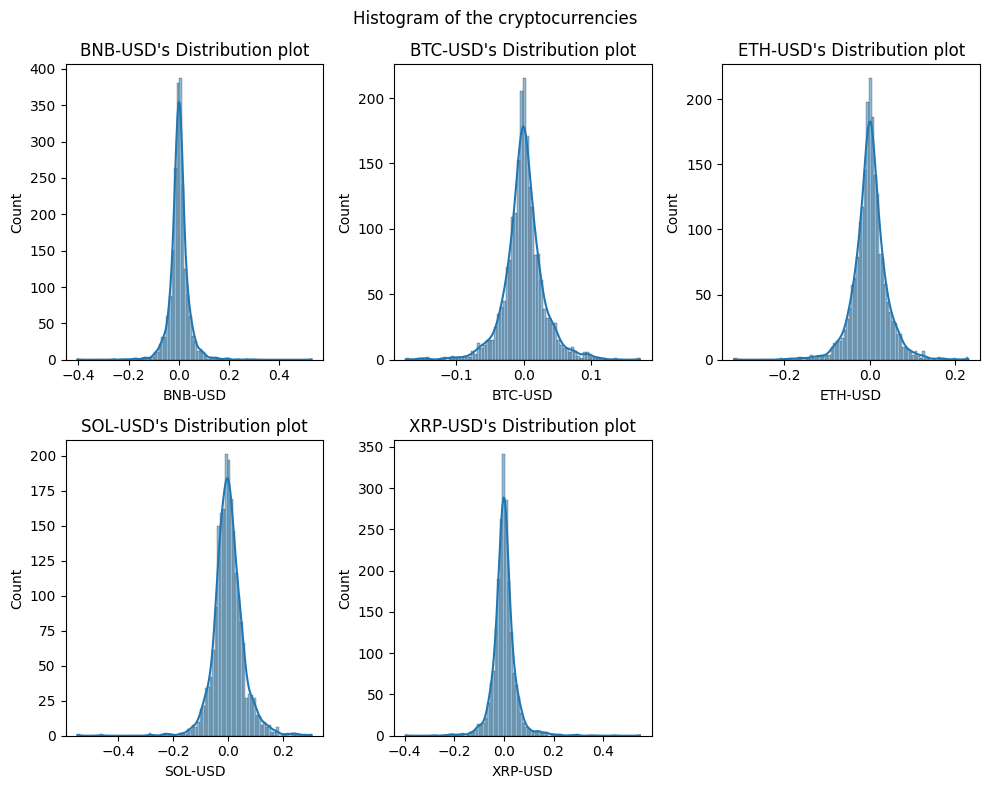

In [18]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(10,8))
ax = ax.ravel()
for i, crypto in enumerate(log_returns.columns):
    sns.histplot(log_returns[crypto], kde=True, ax=ax[i])
    ax[i].set_title(f'{crypto}\'s Distribution plot')

ax[5].set_visible(False)
plt.suptitle('Histogram of the cryptocurrencies')
plt.tight_layout()
plt.show()

## Jacque-Bera test for normality

**Jarque-Bera test (normality)**

$$H_0: \text{the returns are normally distributed }$$
$$H_1: \text{the returns are not normally distributed}$$

Test statistic:

$$JB = \frac{T}{6}\left(S^2 + \frac{(K-3)^2}{4}\right) \sim \chi^2(2)$$

where $T$ is the number of observations, $S$ is the skewness and $K$ is the kurtosis.

Decision rule: reject $H_0$ if $JB > \chi^2_{2,\,0.95} = 5.99$, or equivalently if the $p$-value $< 0.05$.

In [19]:
stats = pd.DataFrame({
    'skew': log_returns.skew(),
    'excess kurt': log_returns.kurt(),
    'JB p': [jarque_bera(log_returns[c])[1] for c in log_returns.columns],
})
print(stats.round(4))

           skew  excess kurt  JB p
BNB-USD  0.8746      24.5642   0.0
BTC-USD -0.1292       4.1395   0.0
ETH-USD -0.1798       5.4511   0.0
SOL-USD -0.3637       9.1606   0.0
XRP-USD  1.2475      17.5773   0.0


## LOG Returns and Correlation

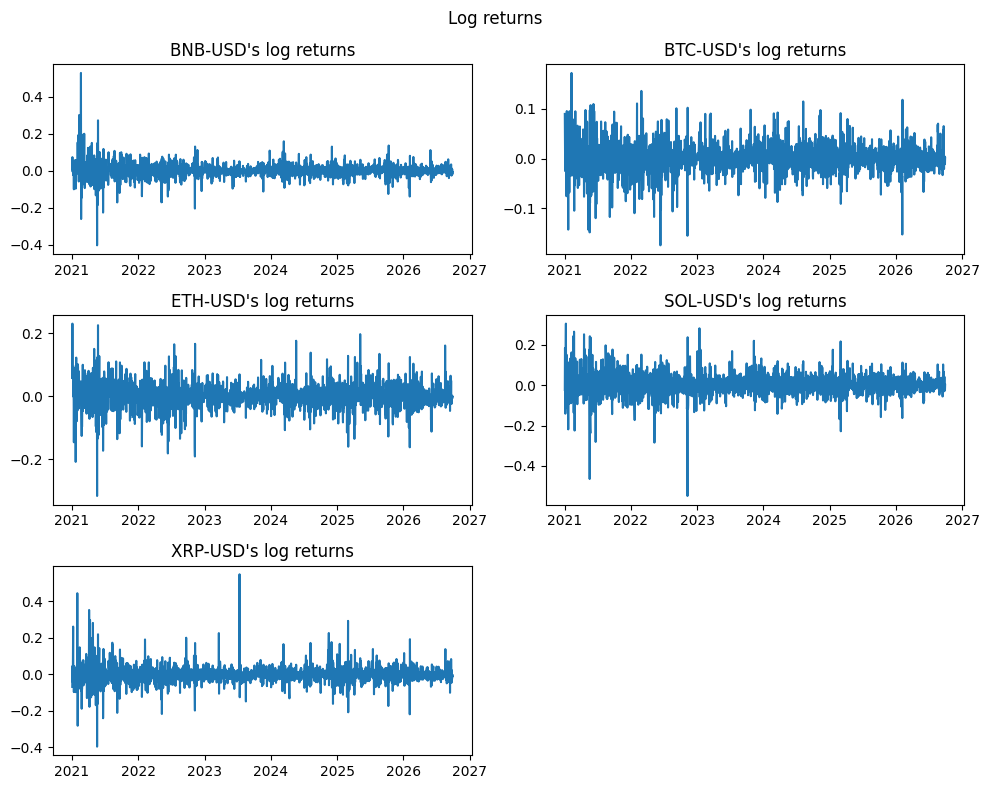

In [20]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(10,8))
ax = ax.ravel()

for i, crypto in enumerate(log_returns.columns):
    ax[i].plot(log_returns[crypto])
    ax[i].set_title(f'{crypto}\'s log returns')
# ax[5].
ax[5].set_visible(False)
plt.suptitle('Log returns')
plt.tight_layout()
plt.show()

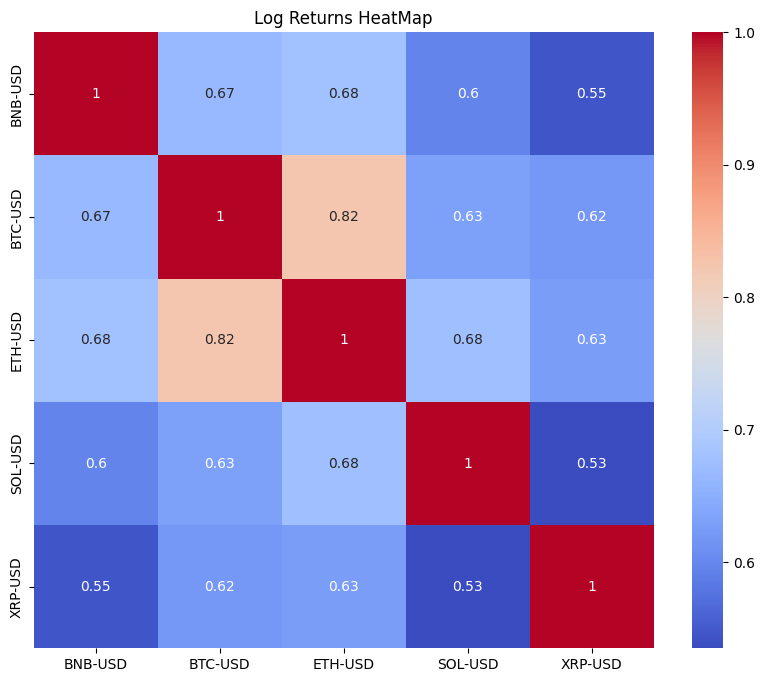

In [21]:
corr_matrix = log_returns.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Log Returns HeatMap')
plt.show()

## Augmented Dickey-Fuller test for stationarity (ADF)

$$\Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta y_{t-i} + \varepsilon_t$$


*   **Null Hypothesis ($H_0$) :** $\gamma = 0$ $\rightarrow$ The series has a unit root; it is **non stationary**
*   **Alternative Hypothèse($H_1$) :** $\gamma < 0$ $\rightarrow$ The series doesn't have a unit root; it is **stationary**

If the **p-value $\leq 0.05$** (or if the test statistic is less than the critical value), we **reject $H_0$** and conclude that the log returns series is **stationary**.


In [22]:
def adf_test(serie):
    adf_res = adfuller(serie)

    print(f'ADF Statistic >> {adf_res[0]}')
    print(f'ADF proba >> {adf_res[1]}')

    if adf_res[1] <= 0.05:
        print('Stationary')
    else:
        print('Not Stationary')

In [23]:
for crypto in log_returns.columns:
    print(f'---{crypto}---')
    adf_test(log_returns[crypto])
    print('-'*30)


---BNB-USD---
ADF Statistic >> -11.648078266763598
ADF proba >> 2.068912934191343e-21
Stationary
------------------------------
---BTC-USD---
ADF Statistic >> -47.523737165715914
ADF proba >> 0.0
Stationary
------------------------------
---ETH-USD---
ADF Statistic >> -47.22919915369839
ADF proba >> 0.0
Stationary
------------------------------
---SOL-USD---
ADF Statistic >> -15.58227676261007
ADF proba >> 1.9259152623201888e-28
Stationary
------------------------------
---XRP-USD---
ADF Statistic >> -47.07836418420833
ADF proba >> 0.0
Stationary
------------------------------


## Engle's Test for ARCH Effects (ARCH-LM Test)

Engle’s Lagrange Multiplier (LM) test is used to check for the presence of autoregressive conditional heteroskedasticity (ARCH effects) in the residuals of a stationary series. First, the residuals $e_t$ are estimated (via a mean regression, or simply by de-meaning the returns), and then an autoregressive regression is fitted on the squared residuals:

$$e_t^2 = \alpha_0 + \alpha_1 e_{t-1}^2 + \alpha_2 e_{t-2}^2 + \dots + \alpha_q e_{t-q}^2 + v_t$$

#### Test Hypotheses:
*   **Null Hypothesis ($H_0$):** $\alpha_1 = \alpha_2 = \dots = \alpha_q = 0$ $\rightarrow$ No ARCH effects (volatility is constant over time).
*   **Alternative Hypothesis ($H_1$):** At least one coefficient $\alpha_i \neq 0$ $\rightarrow$ Presence of ARCH effects (volatility changes over time / clustering).

If the **p-value $\leq 0.05$**, we **reject $H_0$** and confirm the presence of significant ARCH effects. This mathematically justifies the use of a GARCH model.


**Calculating residuals**
$$\varepsilon_t = r_t - \mu$$

In [24]:
resid = log_returns - log_returns.mean()
resid

,BNB-USD,BTC-USD,ETH-USD,SOL-USD,XRP-USD
Date,,,,,
2021-01-02,0.007412,0.089091,0.058096,-0.025502,-0.069686
2021-01-03,0.071847,0.019676,0.230076,0.181547,0.017864
2021-01-04,-0.006853,-0.025521,0.063623,0.137405,0.045958
2021-01-05,0.018128,0.060781,0.055252,-0.143481,-0.043724
2021-01-06,0.008854,0.079523,0.092296,-0.113693,0.100311
...,...,...,...,...,...
2026-09-25,-0.001042,-0.004586,0.000561,0.039861,0.021888
2026-09-26,-0.006026,0.003913,0.001140,-0.006787,-0.026916
2026-09-27,0.005867,0.000113,-0.003699,0.003212,-0.007270


this is a way to determine the number of lags to use in the arch lm test, using the pacf on the squared errors

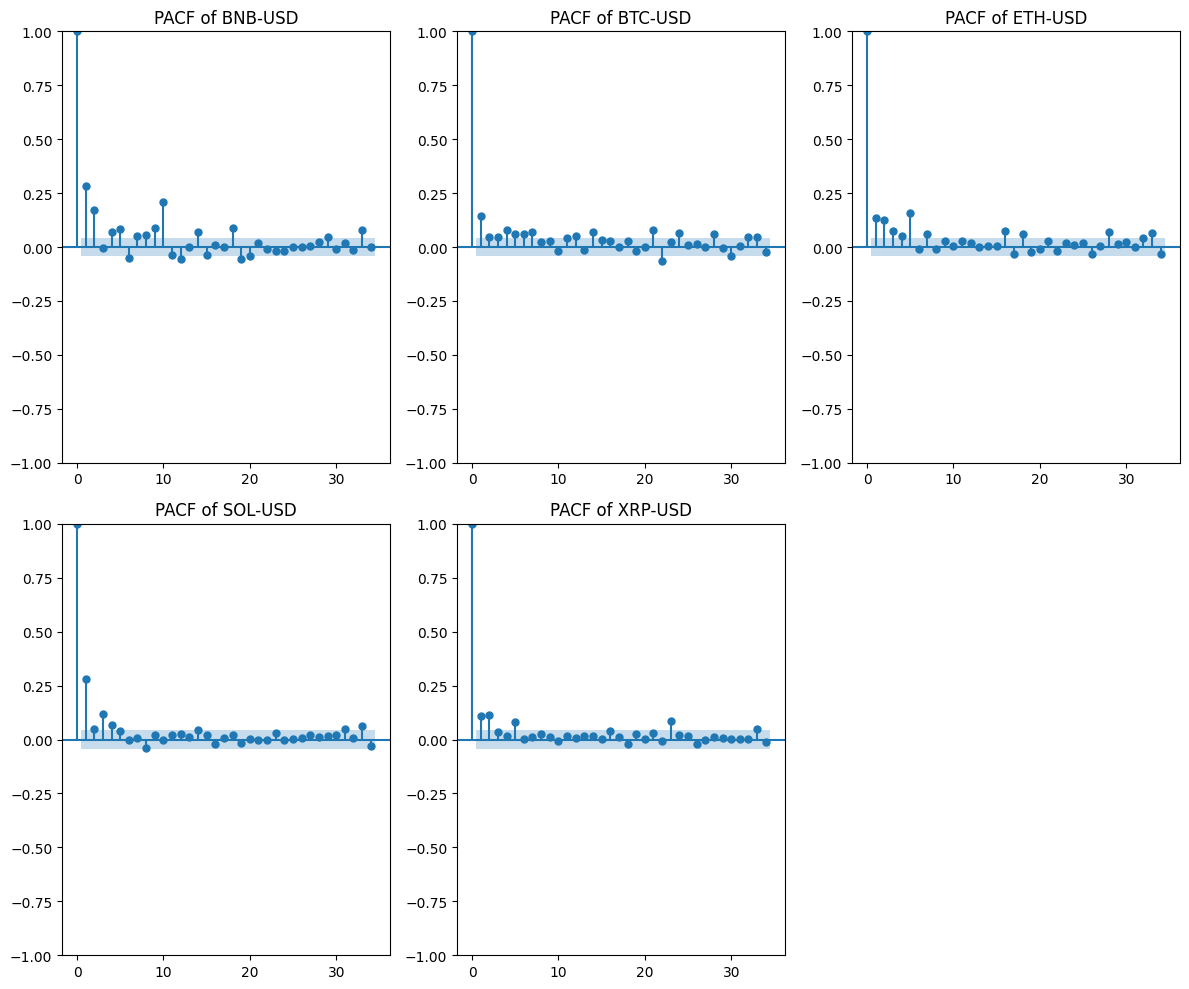

In [25]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12,10))
ax = ax.ravel()
for i, crypto in enumerate(log_returns.columns):
    plot_pacf(resid[crypto]**2, ax=ax[i])
    ax[i].set_title(f'PACF of {crypto}')
ax[5].set_visible(False)
plt.tight_layout()
plt.show()

In [26]:
for crypto in resid.columns:
    print(f'---ARCH-LM for {crypto}---')
    lm_stat, lm_proba, f_stat, f_proba = arch_lm_test = het_arch(resid[crypto], nlags=7)
    print(f'LM_STAT >> {lm_stat}')
    print(f'LM_PROBA >> {lm_proba}')

    if lm_proba <= 0.05:
        print("reject H0(presence of ARCH effects)")
    else:
        print('Fail to reject H0(volatility is constant)')
    print('-'*30)

---ARCH-LM for BNB-USD---
LM_STAT >> 256.4288965657362
LM_PROBA >> 1.1855585031227942e-51
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for BTC-USD---
LM_STAT >> 86.87377210689924
LM_PROBA >> 5.417490391258737e-16
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for ETH-USD---
LM_STAT >> 158.80707598157267
LM_PROBA >> 5.717678846635126e-31
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for SOL-USD---
LM_STAT >> 191.7182244816578
LM_PROBA >> 6.497983452261009e-38
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for XRP-USD---
LM_STAT >> 69.58792982619848
LM_PROBA >> 1.7896259824148515e-12
reject H0(presence of ARCH effects)
------------------------------


## Model Construction
**General view of ARCH(q), GARCH(p) and GJR-GARCH(p,q)**

**ARCH(q)**
$$r_t = \mu + \varepsilon_t, \quad \varepsilon_t = \sigma_t z_t, \quad z_t \sim \mathcal{N}(0,1)$$
$$\sigma_t^2 = \alpha_0 + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2$$

**GARCH(p,q)**

$$\sigma_t^2 = \alpha_0 + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2 + \sum_{j=1}^{p} \beta_j \sigma_{t-j}^2$$

Subject to $\alpha_0 > 0,\ \alpha_i \geq 0,\ \beta_j \geq 0$ and $\sum \alpha_i + \sum \beta_j < 1$.

**GJR-GARCH(p,q)**
\begin{equation}
\sigma_t^2 = \omega + (\alpha + \gamma I_{t-1}) \varepsilon_{t-1}^2 + \beta \sigma_{t-1}^2
\end{equation}

where the indicator function is defined as:
\begin{equation}
I_{t-1} = 
\begin{cases} 
1 & \text{if } \varepsilon_{t-1} < 0 \\
0 & \text{if } \varepsilon_{t-1} \ge 0 
\end{cases}
\end{equation}

{Parameter Constraints:}
\begin{equation}
\omega > 0, \quad \alpha \ge 0, \quad \beta \ge 0, \quad \text{and} \quad \alpha + \gamma \ge 0
\end{equation}

In [27]:
garch_result = {}
lr_pct = log_returns * 100
for crypto in lr_pct.columns:

    print(f'===GARCH MODEL ESTIMATION FOR {crypto}===')
    garch_model = arch_model(lr_pct[crypto], mean='constant', vol='GARCH', p=1,q=1, dist='t')
    result_garch = garch_model.fit(disp='off')
    garch_result[crypto] = result_garch
    
    print(f"-> GARCH Classic AIC: {result_garch.aic:.2f}  | BIC: {result_garch.bic:.2f}")
    print('-'*30)
    print(result_garch.summary())

===GARCH MODEL ESTIMATION FOR BNB-USD===
-> GARCH Classic AIC: 10468.74  | BIC: 10496.98
------------------------------
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                      BNB-USD   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5229.37
Distribution:      Standardized Student's t   AIC:                           10468.7
Method:                  Maximum Likelihood   BIC:                           10497.0
                                              No. Observations:                 2097
Date:                      Sun, Oct 25 2026   Df Residuals:                     2096
Time:                              04:12:49   Df Model:                            1
                                 Mean Model                                
                 coef    std err       

In [28]:
GJRGarch_result = {}
for crypto in lr_pct.columns:
    print(f'===GJR-GARCH MODEL ESTIMATION FOR {crypto}===')
    gjr_garch_model = arch_model(lr_pct[crypto], mean='constant', vol='GARCH', p=1,o=1,q=1, dist='studentst')
    result_gjrgarch = gjr_garch_model.fit(disp='off')
    GJRGarch_result[crypto] = result_gjrgarch

    print(f"-> GJR-GARCH     AIC: {result_gjrgarch.aic:.2f} | BIC: {result_gjrgarch.bic:.2f}")
    print('-'*30)
    print(result_gjrgarch.summary())

===GJR-GARCH MODEL ESTIMATION FOR BNB-USD===
-> GJR-GARCH     AIC: 10470.69 | BIC: 10504.58
------------------------------
                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                      BNB-USD   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -5229.35
Distribution:      Standardized Student's t   AIC:                           10470.7
Method:                  Maximum Likelihood   BIC:                           10504.6
                                              No. Observations:                 2097
Date:                      Sun, Oct 25 2026   Df Residuals:                     2096
Time:                              04:12:49   Df Model:                            1
                                 Mean Model                                
                 coef    std err    

Having AIC/BIC compared for both models

I choosed GARCH

selecting the model that has a lower AIC/BIC and that successfully and simply explains the data without unnecessary parameters.

## ARCH-LM test for GARCH'S residuals

In [29]:
for crypto in lr_pct.columns:
    print(f'---ARCH-LM for {crypto}---')
    std_resid = garch_result[crypto].resid / garch_result[crypto].conditional_volatility
    std_resid = std_resid.dropna()
    lm_stat, lm_proba, f_stat, f_proba = arch_lm_test = het_arch(std_resid, nlags=7)
    print(f'LM_STAT >> {lm_stat}')
    print(f'LM_PROBA >> {lm_proba}')

    if lm_proba <= 0.05:
        print("reject H0(presence of ARCH effects)")
    else:
        print('Fail to reject H0(volatility is constant)')
    print('-'*30)

---ARCH-LM for BNB-USD---
LM_STAT >> 2.5805461223022865
LM_PROBA >> 0.920910733328865
Fail to reject H0(volatility is constant)
------------------------------
---ARCH-LM for BTC-USD---
LM_STAT >> 26.75083871441598
LM_PROBA >> 0.0003694998399076162
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for ETH-USD---
LM_STAT >> 3.714945080383363
LM_PROBA >> 0.8119621601359908
Fail to reject H0(volatility is constant)
------------------------------
---ARCH-LM for SOL-USD---
LM_STAT >> 12.468215189547402
LM_PROBA >> 0.08617509956758783
Fail to reject H0(volatility is constant)
------------------------------
---ARCH-LM for XRP-USD---
LM_STAT >> 0.2869387111438715
LM_PROBA >> 0.9999139615383632
Fail to reject H0(volatility is constant)
------------------------------


Arch effect is not present in all currencies except BTC, this can be explained due to the fact that the btc experienced violent, 

historic volatilty and a single-lag model (1,1) sometimes struggles to absorb 100% of this memory on its own but it's the standard model that is widely used

the fact that there is at least one currencie that conserves the arch effect doesn't make it a failure

especially that it's bitcoin, a currency that have a longer volatility memory.

(also as it'll be presented in the md file, this is for a project not a real institutional model that'll be used.)

## Conditional Value-at-Risk (VaR) Calculation

$$\text{VaR}_t = \mu + z_{\alpha} \cdot \sigma_t$$

*   $\mu$ is the constant mean estimated by the GARCH model.
*   $\sigma_t$ is the conditional volatility for day $t$.
*   $z_{\alpha}$ is the 5th percentile of the standardized Student's t-distribution, based on the estimated degrees of freedom ($\nu$).


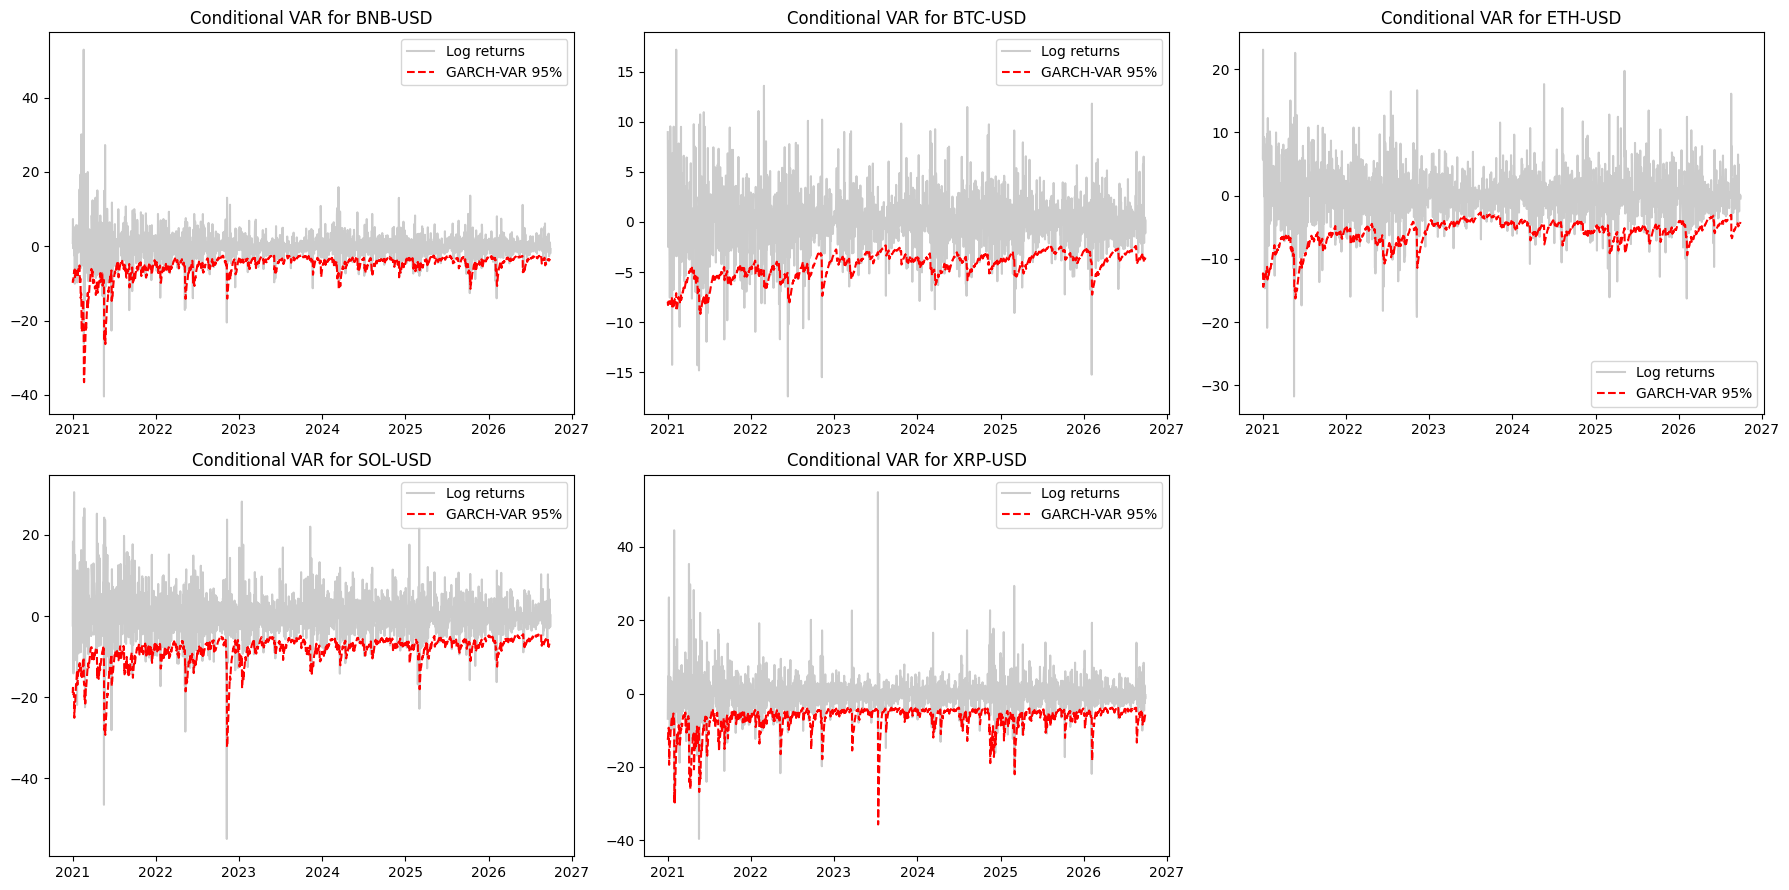

In [30]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(18,9))
ax = ax.ravel()

for i, crypto in enumerate(lr_pct.columns):
    
    mu = garch_result[crypto].params['mu']
    vol_garch = garch_result[crypto].conditional_volatility
    nu = garch_result[crypto].params['nu'] #this is a degree of freedom
    student_quantile = scipy.stats.t.ppf(0.05, df=nu) / np.sqrt(nu/(nu-2))
    
    VAR_95 = mu + student_quantile * vol_garch

    ax[i].plot(lr_pct[crypto] , color='grey', alpha=0.4, label='Log returns')
    ax[i].plot(VAR_95, color='red', linestyle='--', label='GARCH-VAR 95%')

    ax[i].set_title(f'Conditional VAR for {crypto}')
    ax[i].legend()

ax[5].set_visible(False)
plt.tight_layout()
plt.show()


## Backtest of the VAR (kupiec test)

$$LR_{POF} = -2 \ln \left[ \frac{(1 - \alpha)^{N-x} \cdot \alpha^x}{(1 - \hat{p})^{N-x} \cdot \hat{p}^x} \right]$$

*   $N$ is the total number of observations in the backtesting period.
*   $x$ is the total number of observed exceptions ($r_t < \text{VaR}_t$).
*   $\alpha$ is the target theoretical failure probability (for a 95% VaR, $\alpha = 0.05$).
*   $\hat{p} = \frac{x}{N}$ is the actual observed failure rate in the sample.

#### Test Hypothesis:
Under the null hypothesis $H_0$, the $LR_{POF}$ statistic asymptotically follows a Chi-squared distribution with 1 degree of freedom: $LR_{POF} \sim \chi^2(1)$.
*   **Null Hypothesis ($H_0$):** $\hat{p} = \alpha$ $\rightarrow$ The VaR model is statistically accurate (the number of exceptions is correct) [1.1].
*   **Alternative Hypothesis ($H_1$):** $\hat{p} \neq \alpha$ $\rightarrow$ The VaR model is inaccurate (it underestimates or overestimates the actual risk).


At a 5% significance level, the critical value of the Chi-squared distribution with 1 d.o.f. is **3.841**.
*   If **$LR_{POF} > 3.841$** (or if the **p-value $\leq 0.05$**), we **reject $H_0$**.
*   If **$LR_{POF} \leq 3.841$** (or if the **p-value $> 0.05$**), we **fail to reject $H_0$**; the GARCH-VaR model is successfully validated [1.1].


In [31]:
for i, crypto in enumerate(lr_pct.columns):
    mu = garch_result[crypto].params['mu']
    vol_garch = garch_result[crypto].conditional_volatility
    nu = garch_result[crypto].params['nu']
    student_quantile = scipy.stats.t.ppf(0.05, df=nu) / np.sqrt(nu/(nu-2))
    VAR_95 = mu + student_quantile * vol_garch
    
    exceptions = np.sum(lr_pct[crypto] < VAR_95)
    N = len(lr_pct[crypto])
    alpha = 0.05
    x = exceptions
    p_hat = x / N

    LR = -2*np.log(((1-alpha)**(N-x) * alpha**x) / ((1-p_hat)**(N-x) * p_hat**x))
    p_val = 1 - scipy.stats.chi2.cdf(LR, df=1)

    print(f"[{crypto}] Total Days: {N} | Expected Breaches: {int(N*alpha)}")
    print(f"[{crypto}] Observed Breaches: {exceptions}")
    print(f"[{crypto}] Kupiec p-value: {p_val:.4f}")

    if p_val > 0.05:
        print('The VAR model is statistically accurate')
    else:
        print('The VAR model isn\'t accurate')
    print('-'*30)

[BNB-USD] Total Days: 2097 | Expected Breaches: 104
[BNB-USD] Observed Breaches: 108
[BNB-USD] Kupiec p-value: 0.7534
The VAR model is statistically accurate
------------------------------
[BTC-USD] Total Days: 2097 | Expected Breaches: 104
[BTC-USD] Observed Breaches: 107
[BTC-USD] Kupiec p-value: 0.8300
The VAR model is statistically accurate
------------------------------
[ETH-USD] Total Days: 2097 | Expected Breaches: 104
[ETH-USD] Observed Breaches: 114
[ETH-USD] Kupiec p-value: 0.3657
The VAR model is statistically accurate
------------------------------
[SOL-USD] Total Days: 2097 | Expected Breaches: 104
[SOL-USD] Observed Breaches: 92
[SOL-USD] Kupiec p-value: 0.1889
The VAR model is statistically accurate
------------------------------
[XRP-USD] Total Days: 2097 | Expected Breaches: 104
[XRP-USD] Observed Breaches: 107
[XRP-USD] Kupiec p-value: 0.8300
The VAR model is statistically accurate
------------------------------


## Portfolio

In [32]:
weights = np.ones(5)/5

In [33]:
port_log_returns = log_returns @ weights
pct_port = port_log_returns * 100
pct_port

Date
2021-01-02     1.296438
2021-01-03    10.528422
2021-01-04     4.400428
2021-01-05    -0.952673
2021-01-06     3.454025
                ...    
2026-09-25     1.241853
2026-09-26    -0.585327
2026-09-27     0.072669
2026-09-28    -1.434023
2026-09-29    -0.257491
Length: 2097, dtype: float64

In [34]:
GARCH_portfolio = arch_model(pct_port, mean='constant', vol='GARCH',p=1,q=1, dist='t').fit(disp='off')
GARCH_portfolio

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5370.57
Distribution:      Standardized Student's t   AIC:                           10751.1
Method:                  Maximum Likelihood   BIC:                           10779.4
                                              No. Observations:                 2097
Date:                      Sun, Oct 25 2026   Df Residuals:                     2096
Time:                              04:12:51   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [35]:
resid_portfolio = GARCH_portfolio.resid
std_resid_portfolio = resid_portfolio / GARCH_portfolio.conditional_volatility
lm_stat, lm_proba, f_stat, f_proba = arch_lm_test = het_arch(std_resid_portfolio, nlags=7)
print(f'LM_STAT >> {lm_stat}')
print(f'LM_PROBA >> {lm_proba}')

if lm_proba <= 0.05:
    print("reject H0(presence of ARCH effects)")
else:
    print('Fail to reject H0(volatility is constant)')

LM_STAT >> 3.613147714608017
LM_PROBA >> 0.823099757289036
Fail to reject H0(volatility is constant)


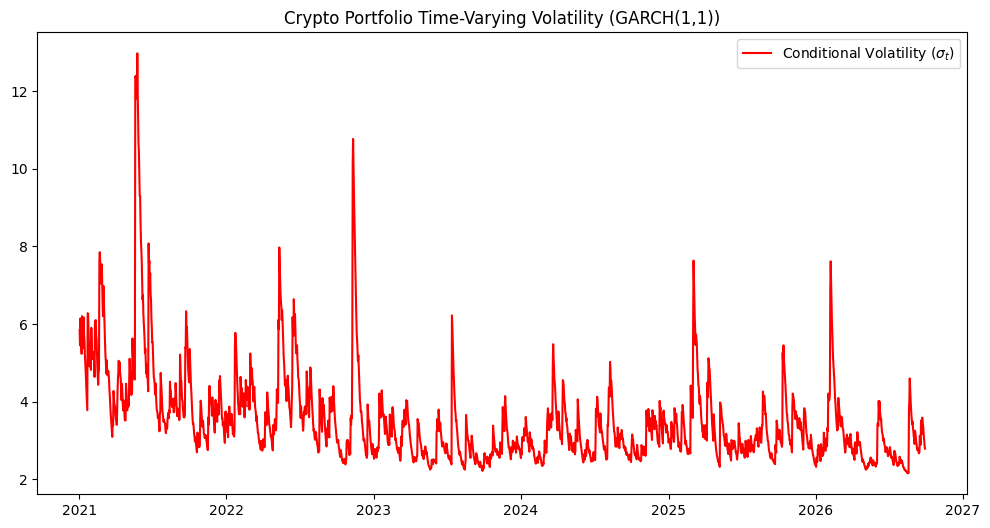

In [36]:
import matplotlib.pyplot as plt

# Extract conditional volatility
cond_vol = GARCH_portfolio.conditional_volatility

# Plot portfolio returns vs estimated volatility
plt.figure(figsize=(12, 6))
plt.plot(port_log_returns.index, cond_vol, color='red', label='Conditional Volatility ($\sigma_t$)')
plt.title('Crypto Portfolio Time-Varying Volatility (GARCH(1,1))')
plt.legend()
plt.show()

In [37]:
forecasts = GARCH_portfolio.forecast(horizon=10)

variance_forecast = forecasts.variance.iloc[-1]
print(variance_forecast)

h.01    7.218064
h.02    7.541108
h.03    7.850987
h.04    8.148239
h.05    8.433377
h.06    8.706895
h.07    8.969267
h.08    9.220947
h.09    9.462370
h.10    9.693955
Name: 2026-09-29 00:00:00, dtype: float64


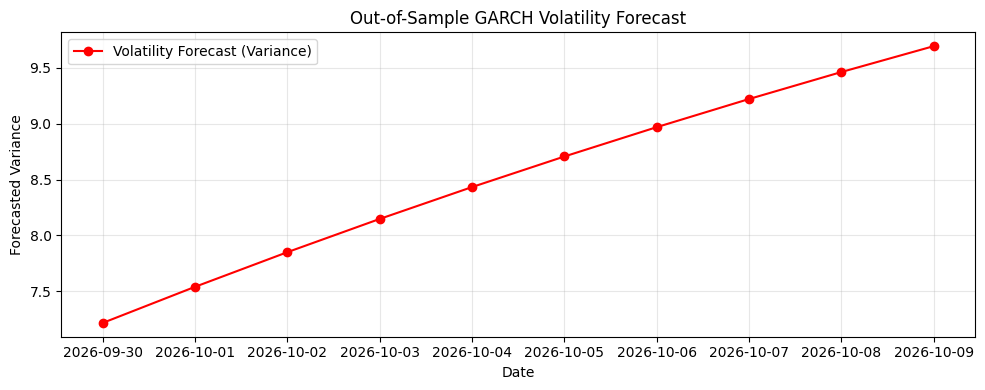

In [39]:
forecasts = GARCH_portfolio.forecast(horizon=10)
variance_forecast = forecasts.variance.iloc[-1]
last_date = port_log_returns.index[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=len(variance_forecast), freq='D')

plt.figure(figsize=(10, 4))
plt.plot(future_dates, variance_forecast, marker='o', color='red', label='Volatility Forecast (Variance)')
plt.title('Out-of-Sample GARCH Volatility Forecast')
plt.xlabel('Date')
plt.ylabel('Forecasted Variance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()